# 01 — Exploratory Data Analysis
### Amazon Food Delivery Time Prediction
Target: `Delivery_Time` (minutes)


In [1]:
import sys
from pathlib import Path

# Make src importable from notebooks/
sys.path.insert(0, str(Path.cwd().parent / "src"))

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from config import (
    RAW_CSV, FIGURES_DIR, TARGET_COL, FIGURE_DPI
)

# ── plot style ─────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams.update({"figure.dpi": FIGURE_DPI, "savefig.dpi": FIGURE_DPI})

print("Libraries loaded ✓")
print(f"Figures will be saved to: {FIGURES_DIR}")


Libraries loaded ✓
Figures will be saved to: C:\Users\ansha\OneDrive\Desktop\ML_Project\reports\figures


## 1 · Load Data

In [2]:
df = pd.read_csv(RAW_CSV)

print("=" * 55)
print(f"Shape          : {df.shape[0]:,} rows × {df.shape[1]} columns")
print("=" * 55)

print("\n── dtypes ──")
print(df.dtypes.to_string())


Shape          : 43,739 rows × 16 columns

── dtypes ──
Order_ID            object
Agent_Age            int64
Agent_Rating       float64
Store_Latitude     float64
Store_Longitude    float64
Drop_Latitude      float64
Drop_Longitude     float64
Order_Date          object
Order_Time          object
Pickup_Time         object
Weather             object
Traffic             object
Vehicle             object
Area                object
Delivery_Time        int64
Category            object


## 2 · Missing Values

In [3]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"missing_count": missing, "missing_%": missing_pct})
missing_df = missing_df[missing_df["missing_count"] > 0]
print("Columns with missing values:")
print(missing_df.to_string())


Columns with missing values:


              missing_count  missing_%
Agent_Rating             54       0.12
Weather                  91       0.21


## 3 · Duplicate Rows

In [4]:
n_dupes = df.duplicated().sum()
print(f"Exact duplicate rows: {n_dupes:,}")


Exact duplicate rows: 0


## 4 · Categorical Value Counts

In [5]:
cat_cols = ["Weather", "Traffic", "Vehicle", "Area", "Category"]

for col in cat_cols:
    # Strip whitespace for display (raw data has trailing spaces)
    vc = df[col].str.strip().value_counts(dropna=False)
    print(f"\n{'─'*40}")
    print(f"  {col}  (unique = {vc.shape[0]})")
    print(f"{'─'*40}")
    print(vc.to_string())



────────────────────────────────────────
  Weather  (unique = 7)
────────────────────────────────────────
Weather
Fog           7440
Stormy        7374
Cloudy        7288
Sandstorms    7245
Windy         7223
Sunny         7078
NaN             91

────────────────────────────────────────
  Traffic  (unique = 5)
────────────────────────────────────────
Traffic
Low       14999
Jam       13725
Medium    10628
High       4296
NaN          91

────────────────────────────────────────
  Vehicle  (unique = 4)
────────────────────────────────────────
Vehicle
motorcycle    25527
scooter       14639
van            3558
bicycle          15

────────────────────────────────────────
  Area  (unique = 4)
────────────────────────────────────────
Area
Metropolitian    32698
Urban             9751
Other             1138
Semi-Urban         152



────────────────────────────────────────
  Category  (unique = 16)
────────────────────────────────────────
Category
Electronics     2849
Books           2824
Jewelry         2802
Toys            2781
Skincare        2772
Snacks          2770
Outdoors        2747
Apparel         2726
Sports          2719
Grocery         2691
Pet Supplies    2690
Home            2685
Cosmetics       2677
Kitchen         2673
Clothing        2667
Shoes           2666


## 5 · Target Distribution: `Delivery_Time`

Saved → C:\Users\ansha\OneDrive\Desktop\ML_Project\reports\figures\01_target_distribution.png


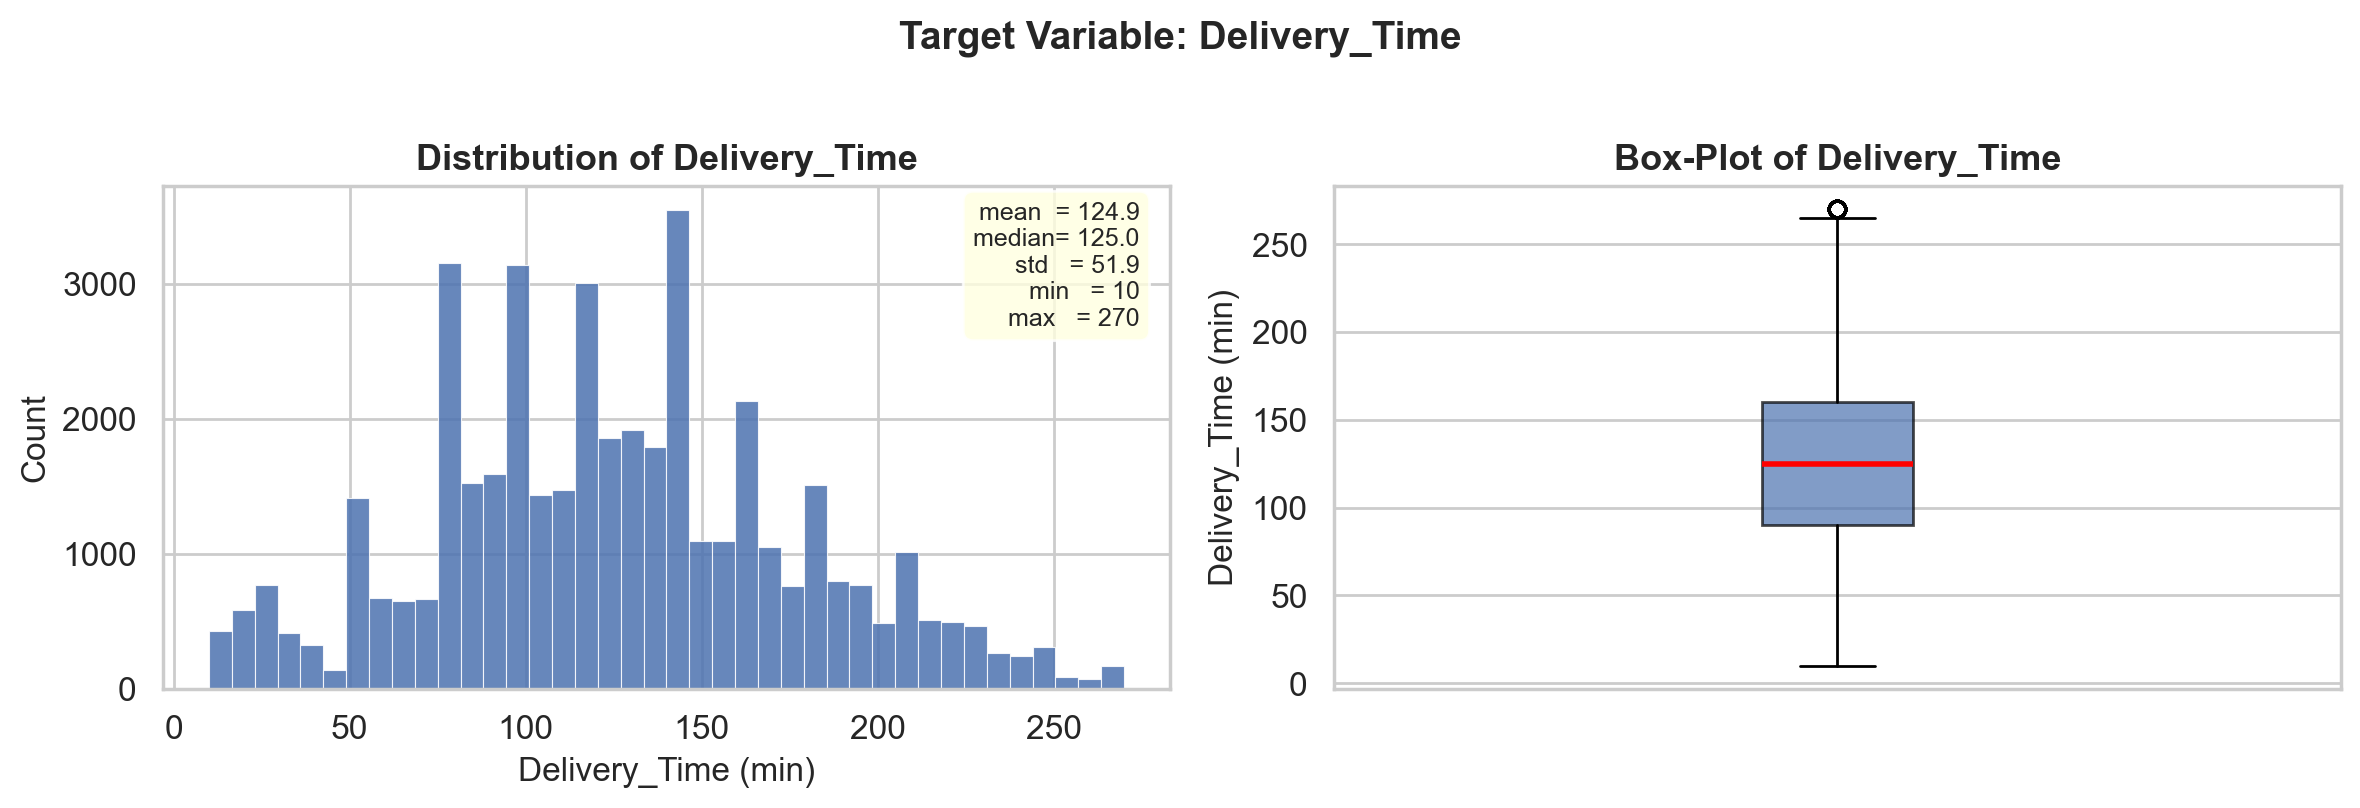

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# histogram + KDE
axes[0].hist(
    df[TARGET_COL], bins=40, color="#4C72B0", edgecolor="white",
    linewidth=0.4, alpha=0.85
)
axes[0].set_xlabel("Delivery_Time (min)", fontsize=12)
axes[0].set_ylabel("Count", fontsize=12)
axes[0].set_title("Distribution of Delivery_Time", fontsize=13, fontweight="bold")

# add stats box
stats = df[TARGET_COL].describe()
textstr = (
    f"mean  = {stats['mean']:.1f}\n"
    f"median= {stats['50%']:.1f}\n"
    f"std   = {stats['std']:.1f}\n"
    f"min   = {stats['min']:.0f}\n"
    f"max   = {stats['max']:.0f}"
)
axes[0].text(
    0.97, 0.97, textstr, transform=axes[0].transAxes,
    fontsize=9, verticalalignment="top", horizontalalignment="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="lightyellow", alpha=0.8),
)

# Q-Q plot style — box plot to check shape
axes[1].boxplot(
    df[TARGET_COL].dropna(), vert=True,
    patch_artist=True,
    boxprops=dict(facecolor="#4C72B0", alpha=0.7),
    medianprops=dict(color="red", linewidth=2),
)
axes[1].set_ylabel("Delivery_Time (min)", fontsize=12)
axes[1].set_title("Box-Plot of Delivery_Time", fontsize=13, fontweight="bold")
axes[1].set_xticks([])

fig.suptitle("Target Variable: Delivery_Time", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()

save_path = FIGURES_DIR / "01_target_distribution.png"
fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
print(f"Saved → {save_path}")
plt.show()


## 6 · Delivery_Time by Traffic Condition

Saved → C:\Users\ansha\OneDrive\Desktop\ML_Project\reports\figures\02_boxplot_delivery_by_traffic.png


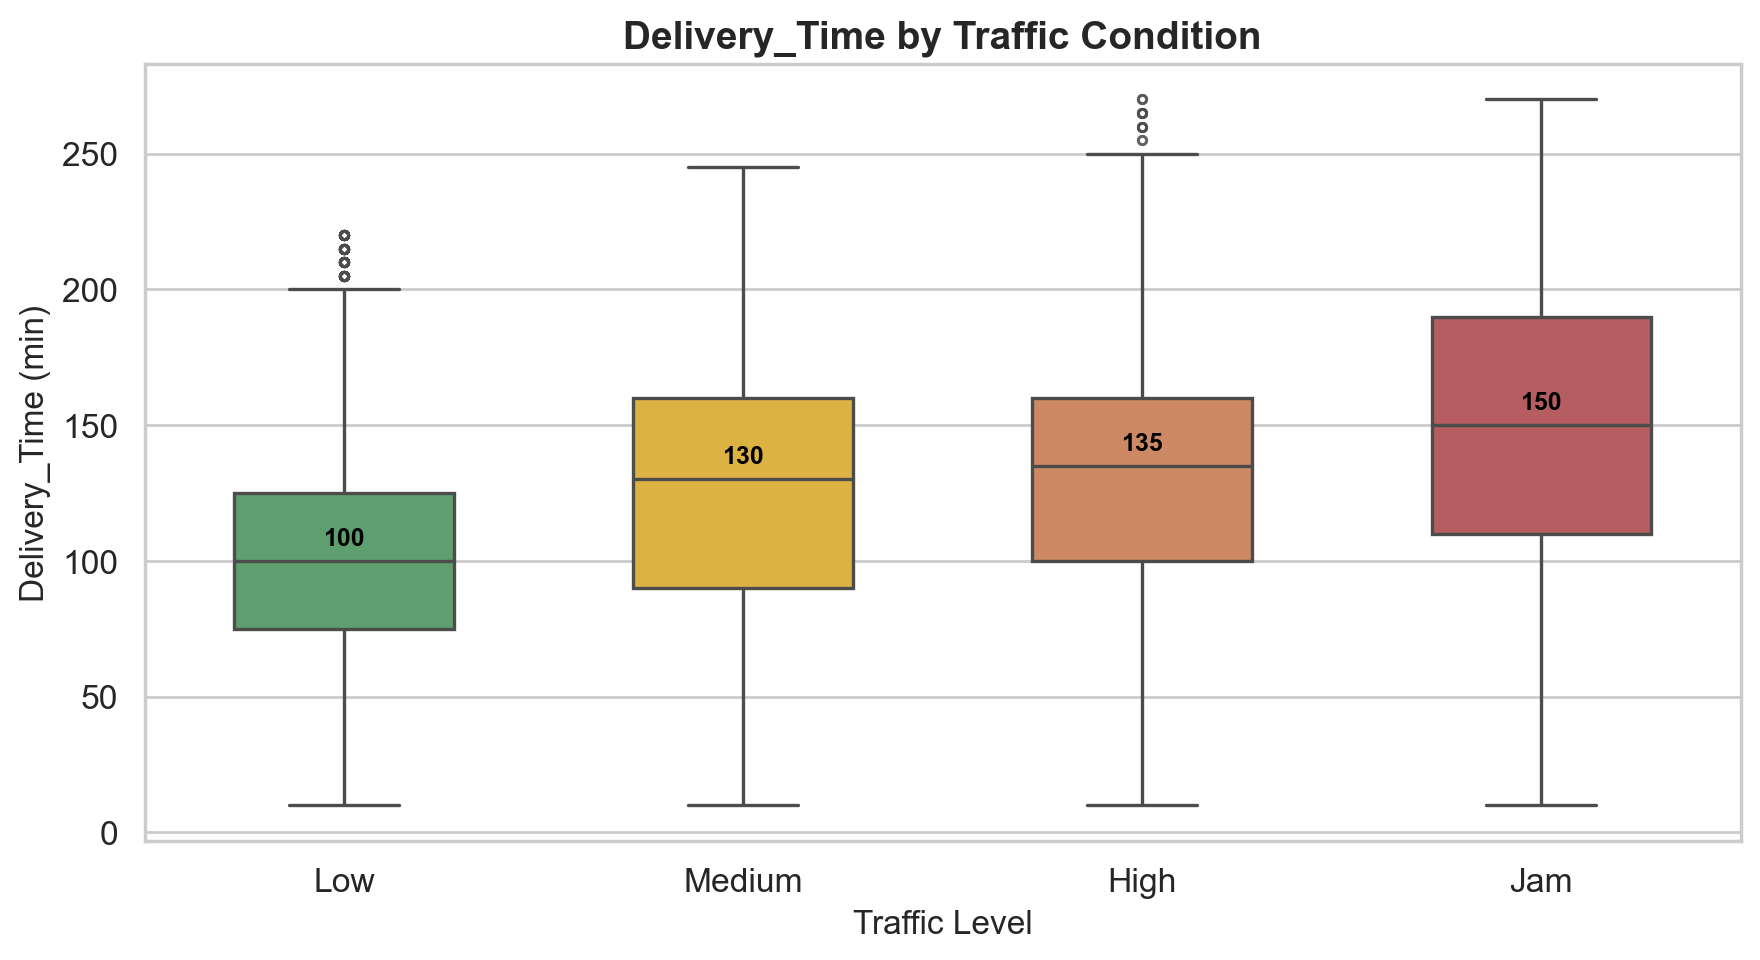

In [7]:
# Strip whitespace in a copy
df_plot = df.copy()
df_plot["Traffic"] = df_plot["Traffic"].str.strip()

traffic_order = ["Low", "Medium", "High", "Jam"]
palette = {
    "Low": "#55a868",
    "Medium": "#f5bf2a",
    "High": "#dd8452",
    "Jam": "#c44e52",
}

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(
    data=df_plot,
    x="Traffic",
    y=TARGET_COL,
    order=traffic_order,
    palette=palette,
    width=0.55,
    linewidth=1.2,
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.4},
    ax=ax,
)
ax.set_title("Delivery_Time by Traffic Condition", fontsize=14, fontweight="bold")
ax.set_xlabel("Traffic Level", fontsize=12)
ax.set_ylabel("Delivery_Time (min)", fontsize=12)

# Annotate medians
for i, lvl in enumerate(traffic_order):
    med = df_plot.loc[df_plot["Traffic"] == lvl, TARGET_COL].median()
    ax.text(i, med + 4, f"{med:.0f}", ha="center", va="bottom",
            fontsize=9, color="black", fontweight="bold")

plt.tight_layout()
save_path = FIGURES_DIR / "02_boxplot_delivery_by_traffic.png"
fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
print(f"Saved → {save_path}")
plt.show()


## 7 · Correlation Heatmap (Numeric Features)

Saved → C:\Users\ansha\OneDrive\Desktop\ML_Project\reports\figures\03_correlation_heatmap.png


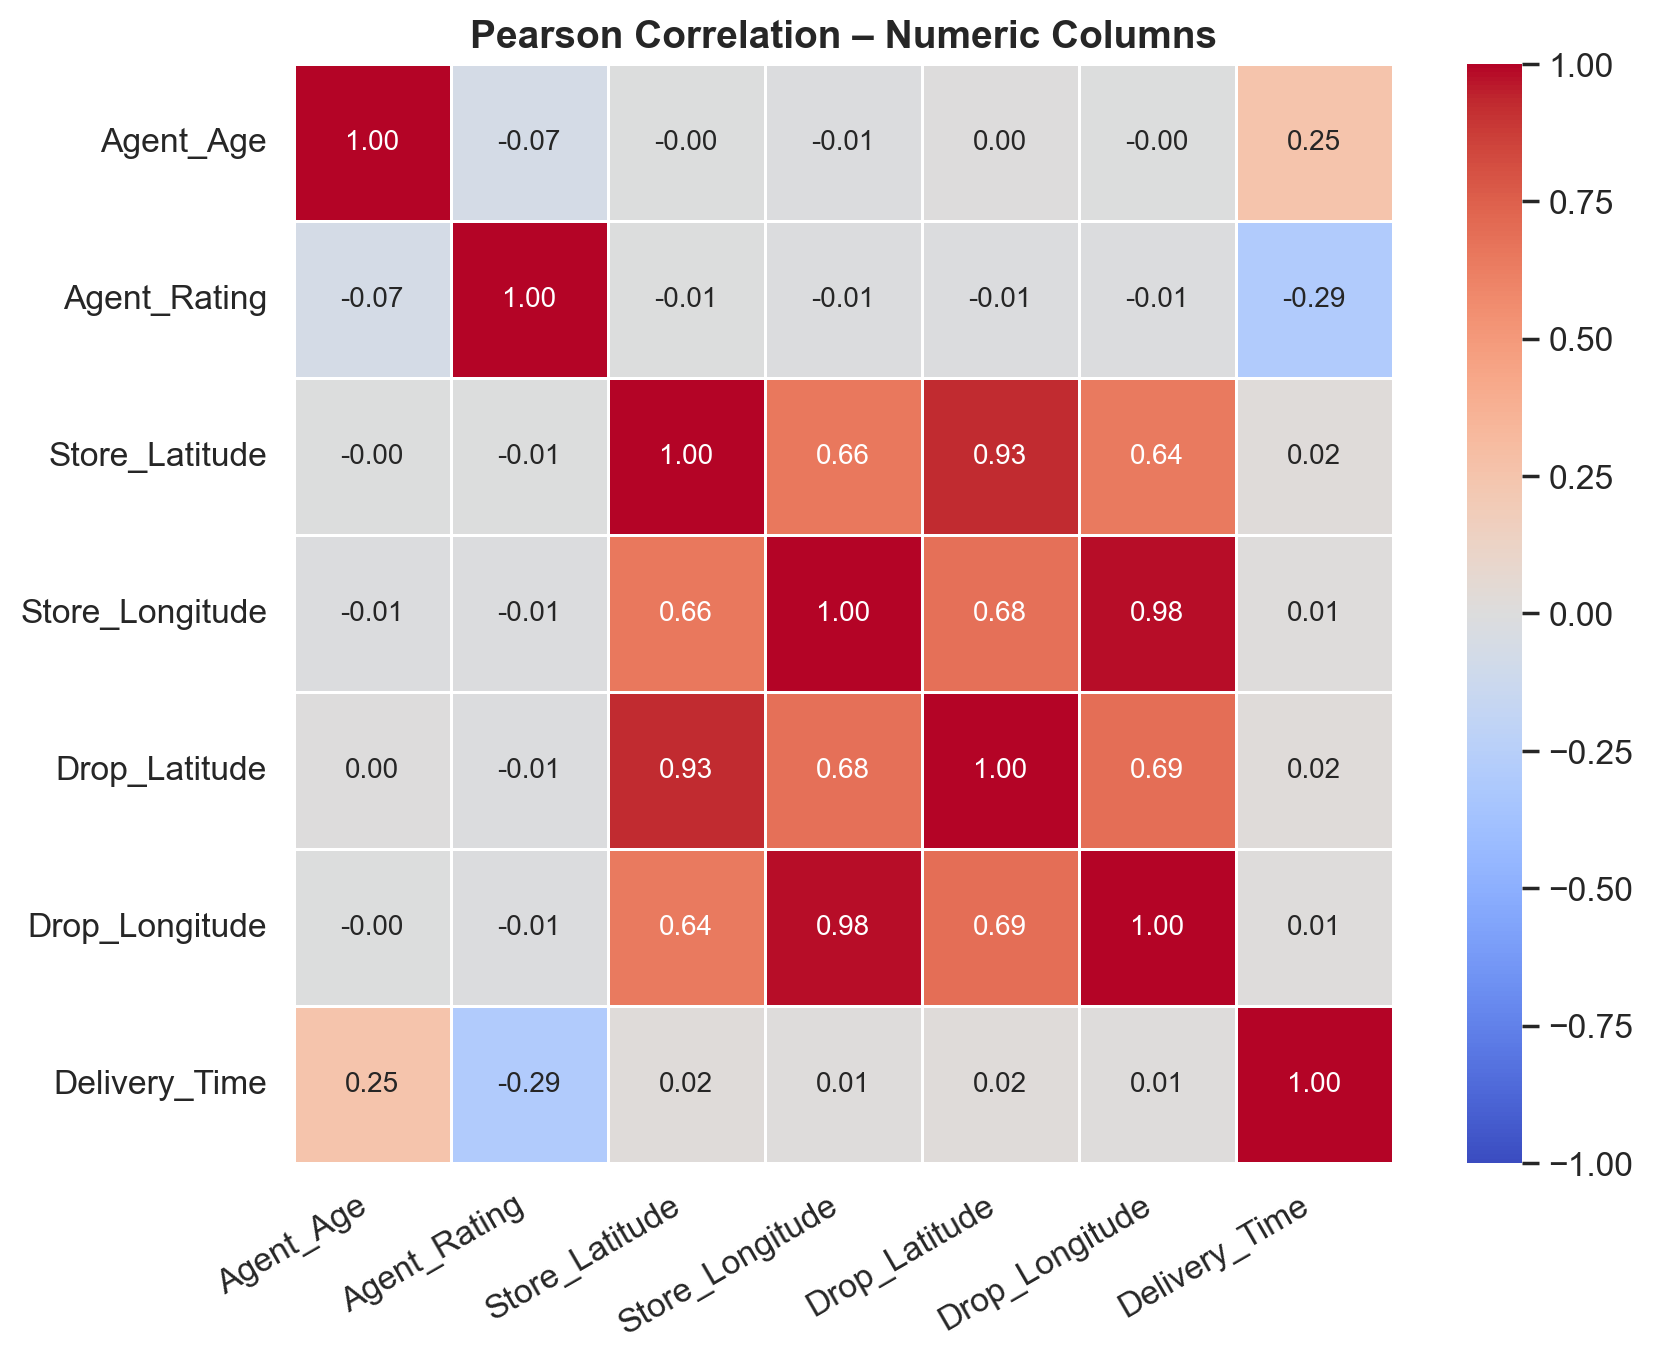

In [8]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # upper triangle

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    linecolor="white",
    square=True,
    ax=ax,
    annot_kws={"size": 10},
)
ax.set_title("Pearson Correlation – Numeric Columns", fontsize=14, fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

save_path = FIGURES_DIR / "03_correlation_heatmap.png"
fig.savefig(save_path, dpi=FIGURE_DPI, bbox_inches="tight")
print(f"Saved → {save_path}")
plt.show()


## 8 · EDA Summary

In [9]:
print("── EDA Summary ──────────────────────────────────────")
print(f"  Total rows          : {len(df):,}")
print(f"  Total columns       : {df.shape[1]}")
print(f"  Columns w/ missings : {(df.isnull().sum() > 0).sum()}")
print(f"  Duplicate rows      : {df.duplicated().sum():,}")
print(f"  Target mean         : {df[TARGET_COL].mean():.1f} min")
print(f"  Target std          : {df[TARGET_COL].std():.1f} min")
print(f"  Target range        : [{df[TARGET_COL].min()}, {df[TARGET_COL].max()}] min")
print("─────────────────────────────────────────────────────")


── EDA Summary ──────────────────────────────────────
  Total rows          : 43,739
  Total columns       : 16
  Columns w/ missings : 2
  Duplicate rows      : 0
  Target mean         : 124.9 min
  Target std          : 51.9 min
  Target range        : [10, 270] min
─────────────────────────────────────────────────────
